# OpenDC Demo 7: Checkpointing

In the [experiment 1](1.first_experiment.ipynb), we learned how to run OpenDC experiments and how to analyze and visualize the results to learn about the behavior of a data center. In this demo, we are using OpenDC to determine the impact of failures on the behaviour of a data center.

In this demo, we will explore how machine failure can impact the performance of a data center. We run the same workload on data centers that are experiencing different levels of machine failure. 

# Failures

Failure causes hosts to stop periodically. In OpenDC, failures can be simulated by providing a trace. 
This trace describes when failures occur, how long they last, and how severe they are (i.e., the number of hosts affected). 

In this demo, we will investigate the effect of failures.

#### Let's start by looking at one of the failure traces.

In [13]:
import pandas as pd

df_failure = pd.read_parquet("failure_traces/Facebook_user_reported.parquet")

df_failure

,failure_interval,failure_duration,failure_intensity
0,0,14400000,1.000000
1,1200000,19200000,1.000000
2,1200000,6000000,0.666667
3,1200000,6000000,1.000000
4,1200000,1200000,0.833333
...,...,...,...
4064,13200000,1200000,0.500000
4065,194400000,2400000,1.000000
4066,280800000,1200000,0.666667
4067,332400000,2400000,0.833333


- *failure_interval* determines the time between failures
- *failure_duration* determines how long a machine cannot be used
- *failure_intensity* determines the ratio of machines affected by the failure.

## Experiment

A user can activate the use of failures by adding it to the Experiment file, as shown below:

```json
{
    "name": "4.failures",
    "topologies": [
        {
            "importFrom": "topologies/4.failures/surfsara.json"
        }
    ],
    "workloads": [
        {
            "type": "trace",
            "source": {
                "type": "named",
                "name": "workload_traces/surf_week"
            }
        }
    ],
    "failureModels": [
        {
            "type": "none"
        },
        {
            "type": "trace",
            "source": {
                "type": "named",
                "name": "failure_traces/Facebook_user_reported.parquet"
            }
        }
    ],
    "exportModels": [
        {
            "exportInterval": "1 h",
            "printFrequency": 24,
            "filesToExport": [
                "host",
                "powerSource",
                "service",
                "task"
            ]
        }
    ]
}
```

Failures are added using the "failureModels" parameter. In this experiment, we run two simulations. One without any failures, and one simulation in which the data center was injected with failures based on the Facebook_user_reported failure trace. 

**Exercise 1:** 
Extend the experiment file located [here](experiments/4.failures/failure_experiment.json) with more failure traces. See the [failure_traces](failure_traces) folder for all available traces.

<details>
<summary>Click to reveal the answer to Exercise 1</summary>

See the [answer experiment file](experiments/4.failures_answers/failure_experiment.json)

In the answers, we added two more failure models. We will use this for the subsequential answers as well.

</details>

# Running an Experiment

An experiment can be run directly from the terminal using the OpenDCExperimentRunner.

In [90]:
import subprocess

pathToExperiment = "experiments/7.checkpointing/checkpointing_experiment.json"
result = subprocess.run(["OpenDCExperimentRunner/bin/opendc", "run", pathToExperiment])

Starting replay


WARN  
					Metrics after 24 hours:
						Tasks Total: 1172
						Tasks Active: 138
						Tasks Pending: 0
						Tasks Completed: 1034
						Tasks Terminated: 0

WARN  
					Metrics after 24 hours:
						Tasks Total: 1172
						Tasks Active: 138
						Tasks Pending: 0
						Tasks Completed: 1034
						Tasks Terminated: 0

WARN  
					Metrics after 24 hours:
						Tasks Total: 1172
						Tasks Active: 138
						Tasks Pending: 0
						Tasks Completed: 1034
						Tasks Terminated: 0

WARN  
					Metrics after 48 hours:
						Tasks Total: 1413
						Tasks Active: 31
						Tasks Pending: 0
						Tasks Completed: 1382
						Tasks Terminated: 0

WARN  
					Metrics after 48 hours:
						Tasks Total: 1413
						Tasks Active: 31
						Tasks Pending: 0
						Tasks Completed: 1382
						Tasks Terminated: 0

WARN  
					Metrics after 48 hours:
						Tasks Total: 1413
						Tasks Active: 31
						Tasks Pending: 0
						Tasks Completed: 1382
						Tasks Terminated: 0

WARN  
					Metrics after 72 ho

Starting replay


WARN  
					Metrics after 24 hours:
						Tasks Total: 1172
						Tasks Active: 141
						Tasks Pending: 0
						Tasks Completed: 1031
						Tasks Terminated: 0

WARN  
					Metrics after 24 hours:
						Tasks Total: 1172
						Tasks Active: 141
						Tasks Pending: 0
						Tasks Completed: 1031
						Tasks Terminated: 0

WARN  
					Metrics after 24 hours:
						Tasks Total: 1172
						Tasks Active: 141
						Tasks Pending: 0
						Tasks Completed: 1031
						Tasks Terminated: 0

WARN  
					Metrics after 48 hours:
						Tasks Total: 1413
						Tasks Active: 34
						Tasks Pending: 0
						Tasks Completed: 1379
						Tasks Terminated: 0

WARN  
					Metrics after 48 hours:
						Tasks Total: 1413
						Tasks Active: 34
						Tasks Pending: 0
						Tasks Completed: 1379
						Tasks Terminated: 0

WARN  
					Metrics after 48 hours:
						Tasks Total: 1413
						Tasks Active: 34
						Tasks Pending: 0
						Tasks Completed: 1379
						Tasks Terminated: 0

WARN  
					Metrics after 72 ho

Starting replay


...

Starting replay


WARN  
					Metrics after 24 hours:
						Tasks Total: 1172
						Tasks Active: 139
						Tasks Pending: 0
						Tasks Completed: 1033
						Tasks Terminated: 0

WARN  
					Metrics after 24 hours:
						Tasks Total: 1172
						Tasks Active: 139
						Tasks Pending: 0
						Tasks Completed: 1033
						Tasks Terminated: 0

WARN  
					Metrics after 24 hours:
						Tasks Total: 1172
						Tasks Active: 139
						Tasks Pending: 0
						Tasks Completed: 1033
						Tasks Terminated: 0

WARN  
					Metrics after 48 hours:
						Tasks Total: 1413
						Tasks Active: 32
						Tasks Pending: 0
						Tasks Completed: 1381
						Tasks Terminated: 0

WARN  
					Metrics after 48 hours:
						Tasks Total: 1413
						Tasks Active: 32
						Tasks Pending: 0
						Tasks Completed: 1381
						Tasks Terminated: 0

WARN  
					Metrics after 48 hours:
						Tasks Total: 1413
						Tasks Active: 32
						Tasks Pending: 0
						Tasks Completed: 1381
						Tasks Terminated: 0

WARN  
					Metrics after 72 ho

Starting replay


WARN  
					Metrics after 24 hours:
						Tasks Total: 1172
						Tasks Active: 141
						Tasks Pending: 0
						Tasks Completed: 1031
						Tasks Terminated: 0

WARN  
					Metrics after 24 hours:
						Tasks Total: 1172
						Tasks Active: 141
						Tasks Pending: 0
						Tasks Completed: 1031
						Tasks Terminated: 0

WARN  
					Metrics after 24 hours:
						Tasks Total: 1172
						Tasks Active: 141
						Tasks Pending: 0
						Tasks Completed: 1031
						Tasks Terminated: 0

WARN  
					Metrics after 48 hours:
						Tasks Total: 1413
						Tasks Active: 34
						Tasks Pending: 0
						Tasks Completed: 1379
						Tasks Terminated: 0

WARN  
					Metrics after 48 hours:
						Tasks Total: 1413
						Tasks Active: 34
						Tasks Pending: 0
						Tasks Completed: 1379
						Tasks Terminated: 0

WARN  
					Metrics after 48 hours:
						Tasks Total: 1413
						Tasks Active: 34
						Tasks Pending: 0
						Tasks Completed: 1379
						Tasks Terminated: 0

WARN  
					Metrics after 72 ho

┌─────────┬──────┬──────┬──────────┬──────────┬────────┬───────────┬──────────┐
│ Scenario│ Seed │ Tasks│ Completed│ Terminate│ Mean CP│ Energy [kW│ Carbon [k│
├─────────┼──────┼──────┼──────────┼──────────┼────────┼───────────┼──────────┤
│ #0      │ 0    │ 5969 │ 5950     │ 19       │ 6.9%   │ 575344.273│ 185206.77│
├─────────┼──────┼──────┼──────────┼──────────┼────────┼───────────┼──────────┤
│ #1      │ 0    │ 5969 │ 5969     │ 0        │ 7.9%   │ 218712.695│ 69899.743│
├─────────┼──────┼──────┼──────────┼──────────┼────────┼───────────┼──────────┤
│ #2      │ 0    │ 5969 │ 5969     │ 0        │ 7.3%   │ 189292.957│ 60568.997│
├─────────┼──────┼──────┼──────────┼──────────┼────────┼───────────┼──────────┤
│ #3      │ 0    │ 5969 │ 5968     │ 1        │ 7.6%   │ 271146.888│ 86925.342│
├─────────┼──────┼──────┼──────────┼──────────┼────────┼───────────┼──────────┤
│ #4      │ 0    │ 5969 │ 5959     │ 10       │ 7.2%   │ 429505.167��� 137428.24│
├─────────┼──────┼──────┼──────────┼──

**Note:** 
Because of the failures, not all tasks are able to be completed. 
When a task fails too many times, it is terminated from the system. This will produce a warning message.

# Output

**Exercise 2:** 
Load the results into Pandas DataFrames


In [64]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Put your code here

In [91]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

checkpointing_models = ["no", "10min", "1h", "10h", "24h", "adaptive"]

df_hosts = {}
df_powerSources = {}
df_tasks = {}
df_services = {}

for i, model in enumerate(checkpointing_models):
    df_hosts[model] = pd.read_parquet(f"output/7.checkpointing/raw-output/{i}/seed=0/host.parquet")
    df_powerSources[model] = pd.read_parquet(f"output/7.checkpointing/raw-output/{i}/seed=0/powerSource.parquet")
    df_tasks[model] = pd.read_parquet(f"output/7.checkpointing/raw-output/{i}/seed=0/task.parquet")
    df_services[model] = pd.read_parquet(f"output/7.checkpointing/raw-output/{i}/seed=0/service.parquet")



<details>
<summary>Click to reveal the answer to Exercise 2</summary>

```python
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


df_host_no = pd.read_parquet("output/7.checkpointing/raw-output/0/seed=0/host.parquet")
df_powerSource_no = pd.read_parquet("output/7.checkpointing/raw-output/0/seed=0/powerSource.parquet")
df_task_no = pd.read_parquet("output/7.checkpointing/raw-output/0/seed=0/task.parquet")
df_service_no = pd.read_parquet("output/7.checkpointing/raw-output/0/seed=0/service.parquet")

df_host_1h = pd.read_parquet("output/7.checkpointing/raw-output/1/seed=0/host.parquet")
df_powerSource_1h = pd.read_parquet("output/7.checkpointing/raw-output/1/seed=0/powerSource.parquet")
df_task_1h = pd.read_parquet("output/7.checkpointing/raw-output/1/seed=0/task.parquet")
df_service_1h = pd.read_parquet("output/7.checkpointing/raw-output/1/seed=0/service.parquet")

df_host_5h = pd.read_parquet("output/7.checkpointing/raw-output/2/seed=0/host.parquet")
df_powerSource_5h = pd.read_parquet("output/7.checkpointing/raw-output/2/seed=0/powerSource.parquet")
df_task_5h = pd.read_parquet("output/7.checkpointing/raw-output/2/seed=0/task.parquet")
df_service_5h = pd.read_parquet("output/7.checkpointing/raw-output/2/seed=0/service.parquet")

df_host_10h = pd.read_parquet("output/7.checkpointing/raw-output/3/seed=0/host.parquet")
df_powerSource_10h = pd.read_parquet("output/7.checkpointing/raw-output/3/seed=0/powerSource.parquet")
df_task_10h = pd.read_parquet("output/7.checkpointing/raw-output/3/seed=0/task.parquet")
df_service_10h = pd.read_parquet("output/7.checkpointing/raw-output/3/seed=0/service.parquet")
```

</details>

# Aggregated metrics

To understand the impact of failures, we can look at some aggregated metrics. 

For this purpose, we suggest using the following metrics:
1. runtime
2. energy_usage
3. carbon_emission

You can also look at some failure specific metrics, such as:
1. tasks_completed
2. tasks_terminated

**Exercise 3:**
Explore the impact of failures using aggregated metrics.

In [66]:
# Your code goes here...

In [101]:
# runtime
for model in checkpointing_models:
    runtime = pd.to_timedelta(df_services[model].timestamp.max(), unit="ms")
    print(f"The workload took {runtime} with {model} checkpointing")
print()

# energy_usage
for model in checkpointing_models:
    energy = df_powerSources[model].energy_usage.max() / 3_600_000 # convert from J to kWh
    print(f"The workload consumed {energy :.2f} kWh with {model} checkpointing")
print()

# carbon_emissions
for model in checkpointing_models:
    carbon = df_powerSources[model].carbon_emission.max() / 1_000 # convert from J to kWh
    print(f"The workload emitted {carbon :.2f} kg of CO2 with {model} checkpointing")

The workload took 12 days 07:40:00 with no checkpointing
The workload took 7 days 16:30:53 with 10min checkpointing
The workload took 7 days 06:43:06 with 1h checkpointing
The workload took 8 days 12:32:48 with 10h checkpointing
The workload took 10 days 15:46:24 with 24h checkpointing
The workload took 8 days 01:16:04.217000 with adaptive checkpointing

The workload consumed 3665.79 kWh with no checkpointing
The workload consumed 2392.31 kWh with 10min checkpointing
The workload consumed 2210.77 kWh with 1h checkpointing
The workload consumed 2626.36 kWh with 10h checkpointing
The workload consumed 3225.67 kWh with 24h checkpointing
The workload consumed 2410.91 kWh with adaptive checkpointing

The workload emitted 1211.37 kg of CO2 with no checkpointing
The workload emitted 760.73 kg of CO2 with 10min checkpointing
The workload emitted 695.10 kg of CO2 with 1h checkpointing
The workload emitted 844.02 kg of CO2 with 10h checkpointing
The workload emitted 1039.21 kg of CO2 with 24h ch

<details>
<summary>Click to reveal the answer to Exercise 3</summary>

``` python
# runtime
runtime_no = pd.to_timedelta(df_service_no.timestamp.max(), unit="ms")
runtime_facebook = pd.to_timedelta(df_service_facebook.timestamp.max(), unit="ms")
runtime_instagram = pd.to_timedelta(df_service_instagram.timestamp.max(), unit="ms")
runtime_netflix = pd.to_timedelta(df_service_netflix.timestamp.max(), unit="ms")


print(f"The workload took {runtime_no} without failures")
print(f"The workload took {runtime_facebook} with facebook failures")
print(f"The workload took {runtime_instagram} with instagram failures")
print(f"The workload took {runtime_netflix} with netflix failures")

# energy_usage
energy_no = df_powerSource_no.energy_usage.max() / 3_600_000 # convert from J to kWh
energy_facebook = df_powerSource_facebook.energy_usage.max() / 3_600_000 # convert from J to kWh
energy_instagram = df_powerSource_instagram.energy_usage.max() / 3_600_000 # convert from J to kWh
energy_netflix = df_powerSource_netflix.energy_usage.max() / 3_600_000 # convert from J to kWh

print(f"The workload consumed {energy_no :.2f} kWh without failures")
print(f"The workload consumed {energy_facebook :.2f} kWh with facebook failures")
print(f"The workload consumed {energy_instagram :.2f} kWh with instagram failures")
print(f"The workload consumed {energy_netflix :.2f} kWh with netflix failures")
```

</details>

# Visualizing failures

The aggregated metrics show that failures can have a big impact on the performance and sustainability of a datacenter. 

Lets use vizualization to further understand what is happening to the datacenter. 

**Exercise 4:** 
Plot the number of tasks during the workload for each of the failure models.

In [25]:
# Your code goes here

<details>
<summary>Click to reveal the answer to Exercise 4</summary>

```python
plt.plot(df_service_no.tasks_active, label="no")
plt.plot(df_service_facebook.tasks_active, label="Facebook")
plt.plot(df_service_instagram.tasks_active, label="Instagram")
plt.plot(df_service_netflix.tasks_active, label="Netflix")

plt.title("Active tasks during a workload")
plt.xlabel("time (h)")
plt.ylabel("active tasks")
plt.legend()
plt.show()
```

</details>

# Service Level Agreement (SLA) violation analysis

In [demo 3](3.horizontal_scaling.ipynb), we determined the impact Horizontal Scaling has on the Service Level Agreements (SLA). 

Lets do a similar thing with our failure model. 

**Exercise 5:** 
Determine the impact of failures on the SLAs 

**Note:** In [demo 3](3.horizontal_scaling.ipynb) it was enough to use just the `scheduling_delay`. However, because we are now dealing with failures, we also need to use the `failure_delay`: The overhead caused by rerunning parts of a task after a failure.

The average scheduling delay with no checkpointing is: 0.73 minutes
The average scheduling delay with 10min checkpointing is: 0.73 minutes
The average scheduling delay with 1h checkpointing is: 0.73 minutes
The average scheduling delay with 10h checkpointing is: 0.73 minutes
The average scheduling delay with 24h checkpointing is: 0.73 minutes
The average scheduling delay with adaptive checkpointing is: 0.73 minutes

The average failure delay with no checkpointing is: 56.17 minutes
The average failure delay with 10min checkpointing is: 0.39 minutes
The average failure delay with 1h checkpointing is: 3.16 minutes
The average failure delay with 10h checkpointing is: 22.18 minutes
The average failure delay with 24h checkpointing is: 39.68 minutes
The average failure delay with adaptive checkpointing is: 5.53 minutes

The average checkpoint delay with no checkpointing is: 0.00 minutes
The average checkpoint delay with 10min checkpointing is: 13.10 minutes
The average checkpoint delay with 1

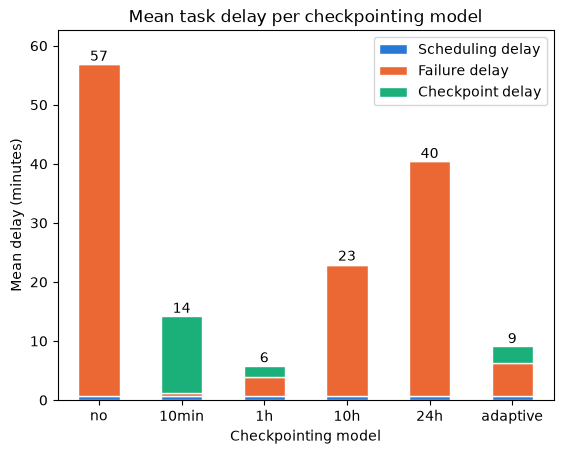

In [100]:
scheduling_delays = {}
failure_delays = {}
checkpoint_delays = {}
total_delays = {}

mean_scheduling_delays = {}
mean_failure_delays = {}
mean_checkpoint_delays = {}
mean_total_delays = {}

for model in checkpointing_models:
    df_tasks[model]["total_delay"] = df_tasks[model]["scheduling_delay"] + df_tasks[model]["failure_delay"] + df_tasks[model]["checkpoint_delay"]

    scheduling_delays[model] = df_tasks[model].groupby('task_id')['scheduling_delay'].agg('max') / 60_000
    failure_delays[model] = df_tasks[model].groupby('task_id')['failure_delay'].agg('max') / 60_000
    checkpoint_delays[model] = df_tasks[model].groupby('task_id')['checkpoint_delay'].agg('max') / 60_000
    total_delays[model] = df_tasks[model].groupby('task_id')['total_delay'].agg('max') / 60_000

    mean_scheduling_delays[model] = scheduling_delays[model].mean()
    mean_failure_delays[model] = failure_delays[model].mean()
    mean_checkpoint_delays[model] = checkpoint_delays[model].mean()
    mean_total_delays[model] = total_delays[model].mean()

# scheduling delay
for model in checkpointing_models:
    print(f"The average scheduling delay with {model} checkpointing is: {scheduling_delays[model].mean():.2f} minutes")

print()
# failure delay
for model in checkpointing_models:
    print(f"The average failure delay with {model} checkpointing is: {failure_delays[model].mean():.2f} minutes")

print()
# checkpoint delay
for model in checkpointing_models:
    print(f"The average checkpoint delay with {model} checkpointing is: {checkpoint_delays[model].mean():.2f} minutes")

print()
# total delay
for model in checkpointing_models:
    print(f"The average total delay with {model} checkpointing is: {total_delays[model].mean():.2f} minutes")



df_delays = pd.DataFrame({
    "Scheduling delay": mean_scheduling_delays,
    "Failure delay": mean_failure_delays,
    "Checkpoint delay": mean_checkpoint_delays,
})

ax = df_delays.plot.bar(stacked=True, color=["#2a78d6", "#eb6834", "#1baf7a"],
                        edgecolor="white", rot=0)

# Total delay on top of each bar
for x, model in enumerate(checkpointing_models):
    ax.text(x, mean_total_delays[model], f"{mean_total_delays[model]:.0f}", ha="center", va="bottom")

ax.set_ylim(top=max(mean_total_delays.values()) * 1.1)  # headroom for the labels
plt.title("Mean task delay per checkpointing model")
plt.xlabel("Checkpointing model")
plt.ylabel("Mean delay (minutes)")
plt.show()

<details>
<summary>Click to reveal the answer to Exercise 6</summary>

```python
plt.plot(df_powerSource_no.energy_usage, label="no")
plt.plot(df_powerSource_facebook.energy_usage, label="Facebook")
plt.plot(df_powerSource_instagram.energy_usage, label="Instagram")
plt.plot(df_powerSource_netflix.energy_usage, label="Netflix")

plt.title("Energy usage during a workload")
plt.xlabel("time [h]")
plt.ylabel("Energy Usage [J]")
plt.legend()
plt.show()
```

</details>